# Exploring the British Airways reviews

Analysis of the British Airways reviews collected by `scraper.ipynb`. I cleaned the review text and scores, summarised ratings by aircraft, traveller type and seat type, and labelled the sentiment of each review with a pretrained Hugging Face model.

Outputs that printed individual reviews have been cleared. The charts and totals are kept.

---

In [1]:
import re
import string

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline

from pprint import pprint

In [68]:
import plotly.express as px

In [2]:
df = pd.read_csv("../data/airline_reviews/british-airways.csv")
df.tail()

In [3]:
df.header = df.header.str.replace('"', "").str.strip()

In [4]:
df.comment = df.comment.str.replace("✅ Verified Review |", "")
df.comment = df.comment.str.replace("Not Verified |", "")
df.comment = df.comment.str.replace("|", "")

In [5]:
def extract_number(x):
    res = re.search(r"\d", str(x))
    if res:
        return res.group()
    else:
        return np.nan

In [6]:
df.food_and_beverages = df.food_and_beverages.apply(lambda x: extract_number(x))

In [7]:
df[
    [
        "seat_comfort",
        "cabin_staff_service",
        "food_and_beverages",
        "ground_service",
        "value_for_money",
        "wifi_and_connecticity",
        "wifi_and_connectivity",
    ]
].sum()

seat_comfort             3127.0
cabin_staff_service      3552.0
ground_service           3191.0
value_for_money          3037.0
wifi_and_connecticity       0.0
wifi_and_connectivity     617.0
dtype: float64

In [10]:
df.header[0]

In [9]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sentiment = SentimentIntensityAnalyzer()

In [46]:
from transformers import pipeline

sentiment_pipeline = pipeline("sentiment-analysis")

In [58]:
df

In [48]:
df

In [119]:
df.food_and_beverages = df.food_and_beverages.astype("Int8")

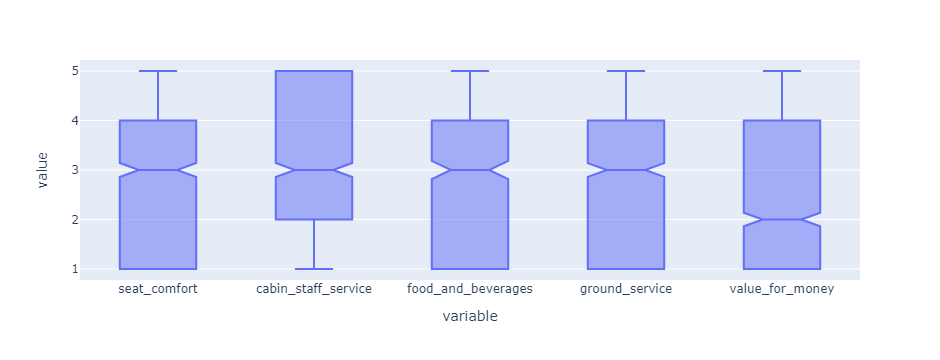

In [126]:
px.box(
    df,
    y=[
        "seat_comfort",
        "cabin_staff_service",
        "food_and_beverages",
        "ground_service",
        "value_for_money",
    ],
    notched=True,
)

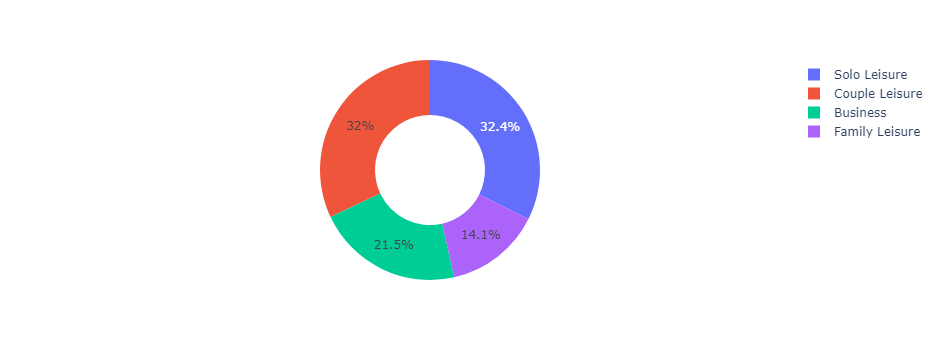

In [103]:
px.pie(
    data_frame=df[["type_of_traveller", "rating"]]
    .groupby("type_of_traveller")
    .count()
    .reset_index(),
    names="type_of_traveller",
    values="rating",
    hole=0.5,
)

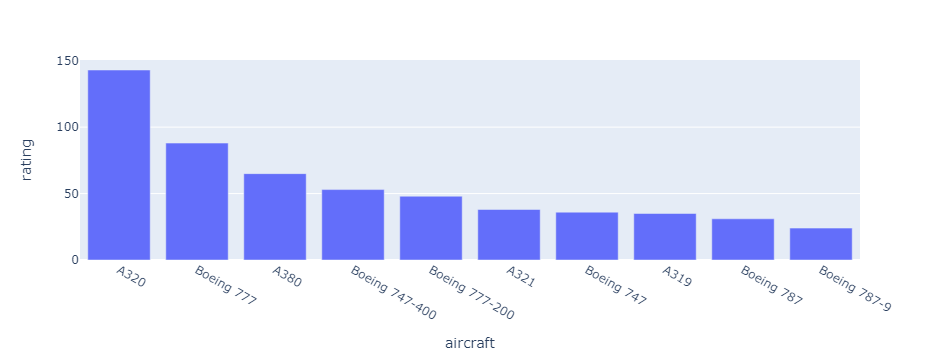

In [97]:
px.bar(
    data_frame=df[["aircraft", "rating"]]
    .groupby("aircraft")
    .count()
    .sort_values(by="rating", ascending=False)
    .head(10)
    .reset_index(),
    x="aircraft",
    y="rating",
)

In [89]:
df[["seat_type", "rating"]].groupby("seat_type").count().reset_index()

,seat_type,rating
0,Business Class,394
1,Economy Class,651
2,First Class,53
3,Premium Economy,102


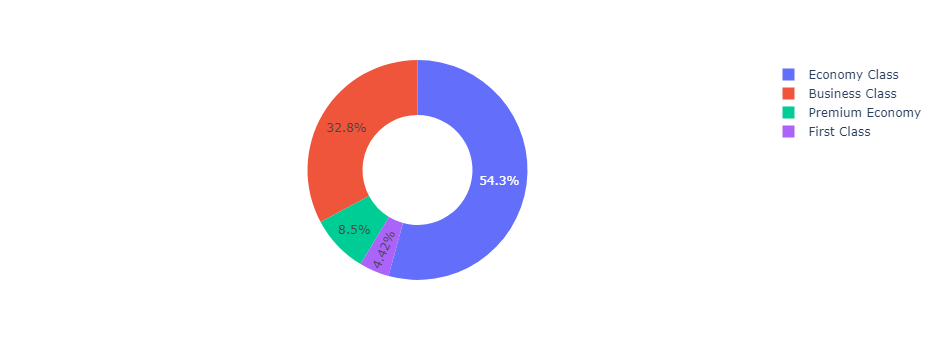

In [90]:
px.pie(
    data_frame=df[["seat_type", "rating"]].groupby("seat_type").count().reset_index(),
    values="rating",
    names="seat_type",
    hole=0.5,
)

,rating,comment
0,1,352
1,2,144
2,3,126
3,4,70
4,5,68
5,6,53
6,7,86
7,8,103
8,9,85
9,10,113


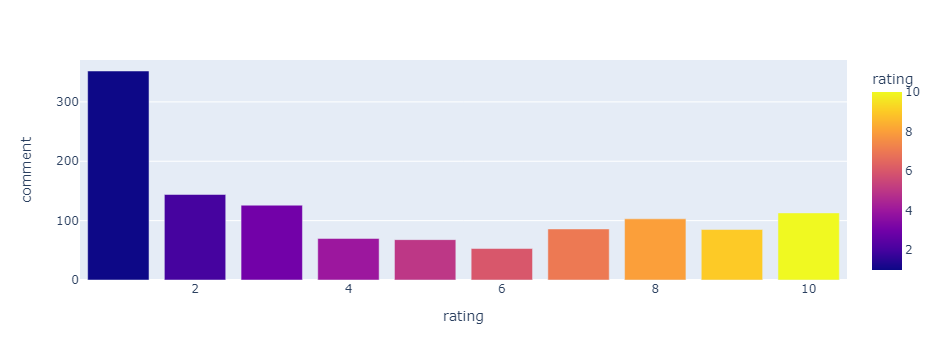

In [134]:
px.bar(
    data_frame=df[["rating", "comment"]].groupby("rating").count().reset_index(),
    x="rating",
    y="comment",
    color="rating",
)

In [136]:
df["sentiment"] = df.agg(
    lambda x: sentiment_pipeline(x.comment[:500])[0]["label"], axis=1
)

In [138]:
df1 = df[["sentiment", "rating"]].groupby("sentiment").count().reset_index()
df1

,sentiment,rating
0,NEGATIVE,866
1,POSITIVE,334


In [140]:
df1.rating = df1.rating / df1.rating.sum()

In [141]:
df1

,sentiment,rating
0,NEGATIVE,0.721667
1,POSITIVE,0.278333


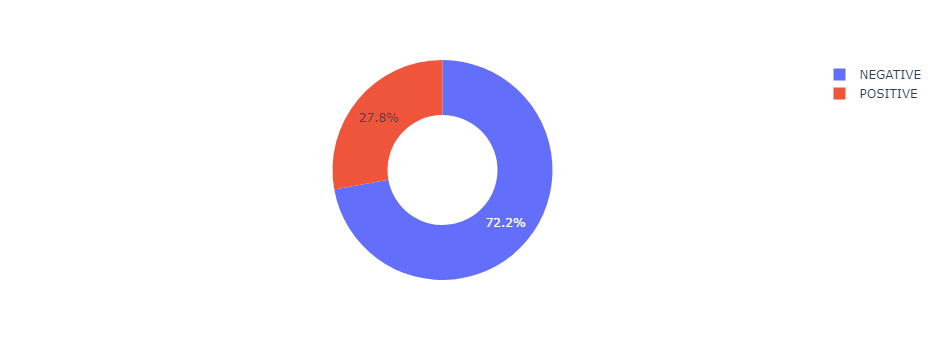

In [144]:
px.pie(data_frame=df1, values="rating", names="sentiment", hole=0.5)